# Analisis kesalahan pipeline notulen

Notebook ini membedah hasil `scripts/evaluate.py` (ringkasannya ada di [reports/results.md](../reports/results.md)) untuk menjawab satu pertanyaan: **kesalahan apa yang paling sering terjadi di tiap tahap, dan mana yang benar-benar salah menurut manusia?**

Bagian:

1. ASR: WER per ucapan, jenis kesalahan, hubungan dengan skor keyakinan model, dan satu kasus VAD.
2. Diarization: DER per file, dan apa yang terjadi saat jumlah pembicara salah ditebak.
3. Ringkasan: skor per dokumen.
4. Tindak lanjut: item yang cocok, terlewat, dan berlebih, serta audit manual.

**Prasyarat:** jalankan `python scripts/evaluate.py` dulu. Notebook hanya membaca `outputs/eval/` dan `data/test_set/`, kecuali bagian VAD yang menjalankan Silero VAD di CPU (beberapa detik).

In [1]:
import json
import warnings
from difflib import SequenceMatcher

import jiwer
import matplotlib.pyplot as plt
import pandas as pd

from notulen.config import PROJECT_ROOT, load_config
from notulen.diarization.diarizer import read_rttm
from notulen.evaluation.action_metrics import item_similarity, match_items, same_owner
from notulen.evaluation.asr_metrics import normalize_text
from notulen.evaluation.diarization_metrics import score_diarization
from notulen.evaluation.test_set import discover, load_summary, reference_text
from notulen.schemas import Summary, Transcript

warnings.filterwarnings("ignore", module="tqdm")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

config = load_config()
evaluation = config.evaluation
OUTPUT_DIR = evaluation.output_dir
if not (OUTPUT_DIR / "results.json").is_file():
    raise FileNotFoundError(f"{OUTPUT_DIR} has no results.json. Run scripts/evaluate.py first.")

items = discover(evaluation.test_set_dir)
results = json.loads((OUTPUT_DIR / "results.json").read_text(encoding="utf-8"))
print(f"{len(items)} item uji, hasil dari {OUTPUT_DIR.relative_to(PROJECT_ROOT).as_posix()}")

110 item uji, hasil dari outputs/eval


## 1. ASR

WER dihitung ulang per ucapan dengan normalisasi yang sama seperti di `evaluate.py` (huruf kecil, tanpa tanda baca, tanda hubung jadi spasi). Hanya subset FLEURS yang dipakai, karena transkrip LibriVox memakai ejaan lama.

Corpus WER: 10.6% dari 100 ucapan
Ucapan tanpa kesalahan: 30 (30%)
Median WER per ucapan: 6.9%


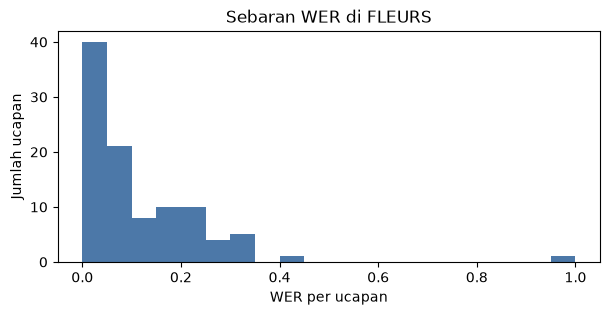

In [2]:
def load_hypothesis(item_id: str) -> Transcript:
    path = OUTPUT_DIR / "asr" / f"{item_id}.json"
    return Transcript.model_validate_json(path.read_text(encoding="utf-8"))


asr_rows = []
alignments = {}
for item in items:
    skip = item.subset in evaluation.wer_exclude_subsets
    if skip or item.audio is None or item.transcript is None:
        continue
    hypothesis = load_hypothesis(item.item_id)
    reference = normalize_text(reference_text(item.transcript))
    hypothesis_text = normalize_text(" ".join(segment.text for segment in hypothesis.segments))
    output = jiwer.process_words(reference, hypothesis_text)
    alignments[item.item_id] = output
    probabilities = [word.probability for segment in hypothesis.segments for word in segment.words]
    asr_rows.append(
        {
            "id": item.item_id,
            "kata_ref": len(reference.split()),
            "wer": output.wer,
            "S": output.substitutions,
            "D": output.deletions,
            "I": output.insertions,
            "keyakinan_rata2": sum(probabilities) / len(probabilities) if probabilities else None,
            "referensi": reference,
            "hipotesis": hypothesis_text,
        }
    )

asr = pd.DataFrame(asr_rows).set_index("id")
errors = asr[["S", "D", "I"]].sum()
print(f"Corpus WER: {errors.sum() / asr.kata_ref.sum():.1%} dari {len(asr)} ucapan")
print(f"Ucapan tanpa kesalahan: {(asr.wer == 0).sum()} ({(asr.wer == 0).mean():.0%})")
print(f"Median WER per ucapan: {asr.wer.median():.1%}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(asr.wer, bins=20, color="#4C78A8")
ax.set_xlabel("WER per ucapan")
ax.set_ylabel("Jumlah ucapan")
ax.set_title("Sebaran WER di FLEURS")
plt.show()

In [3]:
asr.sort_values("wer", ascending=False).head(8)[["wer", "S", "D", "I", "referensi", "hipotesis"]]

,wer,S,D,I,referensi,hipotesis
id,,,,,,
fleurs_009,1.000000,0,15,0,anak anak liar mungkin pernah mengalami pelecehan atau trauma berat sebelum ditelantarkan atau melarikan diri,
fleurs_000,0.423077,10,0,1,greenland berpenduduk jarang di saga nordik dikatakan bahwa erik si merah diasingkan dari islandia akibat pembunuhan...,greenland berapa duduk jarang di saga nordic dikatakan bahwa eriks zimmera dihasingkan dari islam dia akibat umuduka...
fleurs_067,0.350000,4,0,3,kepulauan ini terletak 120 km dari utara semenanjung pulau terbesar adalah pulau king george yang memiliki pemukiman...,kepulauan ini terletak 120 km dari utara semangat nyujung pulau terbesar adalah pulau king george yang memiliki pemu...
fleurs_035,0.333333,4,0,0,bus scotturb 403 rutin berangkat ke sintra berhenti di cabo da roca,bus kota 403 rutin berangkat ke sintra berhenti di kabo dan roka
fleurs_060,0.333333,4,1,1,pada bulan yang sama maskapai lain melewati landasan pacu di masyhad dan menabrak dinding menewaskan tujuh belas orang,pada bulan yang sama mas kapai layan melewati landasan pacu di masyad dan menabrak dinding menewaskan 17 orang
fleurs_079,0.333333,5,1,1,sundarbans merupakan sabuk bakau pesisir yang terbesar di dunia membentang 80 km 50 mil dari pesisir ke pedalaman ba...,sundar bans merupakan sabuk baku pisisir yang terbesar di dunia membentang 80 km 50 mil dari pisisir kepedalaman ban...
fleurs_023,0.312500,2,0,3,tumbuhan menghasilkan oksigen yang dihirup manusia dan mereka menghirup karbondioksida yang dikeluarkan manusia yang...,tumbuhan menghasilkan oksigen yang dihirup manusia dan mereka menghirup karbon dioksida yang dikeluarkan manusia dal...
fleurs_056,0.296296,7,1,0,mitchell gourley dari australia selesai di posisi sebelas dari super g berdiri pria kompetitor ceko oldrich jelinek ...,michelle golny dari australia selesai di posisi 11 dari super g berdiri pria kompetitor ceko aldrik jeminet selesai ...


### Jenis kesalahan

Setiap rentang kata yang tidak cocok (gabungan substitusi, hapus, dan sisip yang berdampingan) dikelompokkan dengan aturan sederhana, diperiksa berurutan:

1. **Terhapus seluruhnya**: hipotesis kosong untuk seluruh ucapan.
2. **Angka**: salah satu sisi berisi digit atau kata bilangan ("dua" lawan "2").
3. **Spasi**: huruf sama, hanya batas katanya beda ("karbondioksida" lawan "karbon dioksida").
4. **Ejaan mirip**: kemiripan karakter minimal 0.7 ("pesisir" lawan "pisisir", "pakaian" lawan "pakean").
5. **Lainnya**: salah dengar yang mengubah kata, sering pada nama diri asing.

In [4]:
NUMBER_WORDS = {
    "nol",
    "satu",
    "dua",
    "tiga",
    "empat",
    "lima",
    "enam",
    "tujuh",
    "delapan",
    "sembilan",
    "sepuluh",
    "sebelas",
    "belas",
    "puluh",
    "ratus",
    "ribu",
    "juta",
    "miliar",
    "seratus",
    "seribu",
}


def error_regions(output):
    """Merge adjacent non-equal alignment chunks into (ref_words, hyp_words, errors) regions."""
    ref_words, hyp_words = output.references[0], output.hypotheses[0]
    regions, current = [], None
    for chunk in output.alignments[0]:
        if chunk.type == "equal":
            if current:
                regions.append(current)
            current = None
            continue
        ref_part, hyp_part = [], []
        if chunk.type != "insert":
            ref_part = ref_words[chunk.ref_start_idx : chunk.ref_end_idx]
        if chunk.type != "delete":
            hyp_part = hyp_words[chunk.hyp_start_idx : chunk.hyp_end_idx]
        count = len(ref_part) if chunk.type != "insert" else len(hyp_part)
        if current is None:
            current = ([], [], 0)
        current = (current[0] + ref_part, current[1] + hyp_part, current[2] + count)
    if current:
        regions.append(current)
    return regions


def classify(ref_part, hyp_part, whole_utterance_empty):
    if whole_utterance_empty:
        return "terhapus seluruhnya"
    tokens = ref_part + hyp_part
    if any(token.isdigit() or token in NUMBER_WORDS for token in tokens):
        return "angka"
    joined_ref, joined_hyp = "".join(ref_part), "".join(hyp_part)
    if joined_ref and joined_ref == joined_hyp:
        return "spasi"
    if joined_ref and joined_hyp and SequenceMatcher(None, joined_ref, joined_hyp).ratio() >= 0.7:
        return "ejaan mirip"
    return "lainnya"


region_rows = []
for item_id, output in alignments.items():
    empty = not output.hypotheses[0]
    for ref_part, hyp_part, count in error_regions(output):
        region_rows.append(
            {
                "id": item_id,
                "jenis": classify(ref_part, hyp_part, empty),
                "kesalahan": count,
                "referensi": " ".join(ref_part),
                "hipotesis": " ".join(hyp_part),
            }
        )

regions = pd.DataFrame(region_rows)
by_type = (
    regions.groupby("jenis")["kesalahan"]
    .agg(["sum", "count"])
    .rename(columns={"sum": "kesalahan_kata", "count": "rentang"})
    .sort_values("kesalahan_kata", ascending=False)
)
by_type["porsi"] = (by_type.kesalahan_kata / by_type.kesalahan_kata.sum()).map("{:.0%}".format)
by_type

,kesalahan_kata,rentang,porsi
jenis,,,
ejaan mirip,121,82,58%
lainnya,43,31,20%
angka,17,9,8%
terhapus seluruhnya,15,1,7%
spasi,14,7,7%


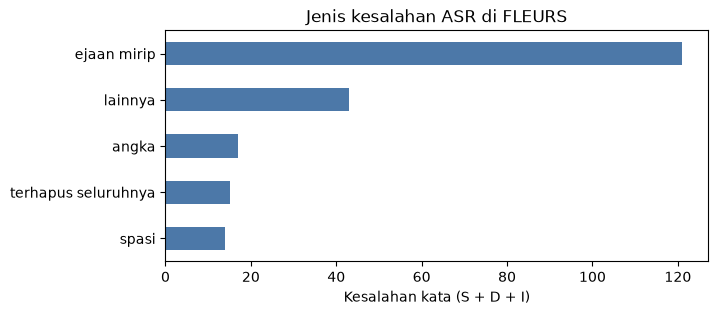

--- ejaan mirip
  fleurs_000: 'berpenduduk' -> 'berapa duduk'
  fleurs_000: 'nordik' -> 'nordic'
  fleurs_000: 'erik si merah diasingkan dari islandia' -> 'eriks zimmera dihasingkan dari islam dia'
  fleurs_000: 'menamakannya' -> 'menanamkannya'
--- lainnya
  fleurs_000: 'pembunuhan' -> 'umudukan'
  fleurs_004: 'label' -> 'level'
  fleurs_005: 'finch' -> 'vince'
  fleurs_017: 'dan' -> 'dari'
--- angka
  fleurs_005: 'dua' -> '2'
  fleurs_025: '1000 1300 m' -> 'sampai 11300 masehi'
  fleurs_052: 'kesepuluh' -> 'ke 10'
  fleurs_056: 'sebelas' -> '11'
--- terhapus seluruhnya
  fleurs_009: 'anak anak liar mungkin pernah mengalami pelecehan atau trauma berat sebelum ditelantarkan atau melarikan diri' -> ''
--- spasi
  fleurs_007: 'diawasi' -> 'di awasi'
  fleurs_022: 'perancah' -> 'peran cah'
  fleurs_023: 'karbondioksida' -> 'karbon dioksida'
  fleurs_043: 'ibu kota' -> 'ibukota'


In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
by_type.kesalahan_kata.sort_values().plot.barh(ax=ax, color="#4C78A8")
ax.set_xlabel("Kesalahan kata (S + D + I)")
ax.set_ylabel("")
ax.set_title("Jenis kesalahan ASR di FLEURS")
plt.show()

for kind in by_type.index:
    sample = regions[regions.jenis == kind].head(4)
    print(f"--- {kind}")
    for row in sample.itertuples():
        print(f"  {row.id}: '{row.referensi}' -> '{row.hipotesis}'")

Sebagian kesalahan "angka" sebenarnya bukan salah dengar: Whisper menulis "17" saat referensi menulis "tujuh belas". Berapa WER jika kesalahan format angka dan spasi tidak dihitung?

In [6]:
formatting = by_type.loc[by_type.index.intersection(["angka", "spasi"]), "kesalahan_kata"].sum()
total_errors = by_type.kesalahan_kata.sum()
print(f"WER apa adanya:              {total_errors / asr.kata_ref.sum():.1%}")
print(f"Tanpa kesalahan angka/spasi: {(total_errors - formatting) / asr.kata_ref.sum():.1%}")
print("(Batas atas yang kasar: tidak semua rentang 'angka' hanya beda format.)")

WER apa adanya:              10.6%
Tanpa kesalahan angka/spasi: 9.0%
(Batas atas yang kasar: tidak semua rentang 'angka' hanya beda format.)


### Apakah skor keyakinan Whisper memberi tanda?

Jika keyakinan rata-rata kata rendah pada ucapan yang salah, skor ini bisa dipakai untuk menandai bagian transkrip yang perlu dicek manusia.

Korelasi Spearman keyakinan vs WER: -0.67 (n=99)


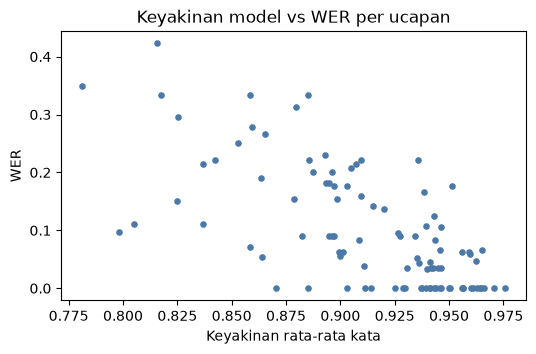

Median WER 20% ucapan paling tidak yakin: 21.8%
Median WER sisanya:                       5.3%


In [7]:
scored = asr.dropna(subset=["keyakinan_rata2"])
correlation = scored[["keyakinan_rata2", "wer"]].corr(method="spearman").iloc[0, 1]
print(f"Korelasi Spearman keyakinan vs WER: {correlation:.2f} (n={len(scored)})")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(scored.keyakinan_rata2, scored.wer, s=14, color="#4C78A8")
ax.set_xlabel("Keyakinan rata-rata kata")
ax.set_ylabel("WER")
ax.set_title("Keyakinan model vs WER per ucapan")
plt.show()

low = scored.keyakinan_rata2 < scored.keyakinan_rata2.quantile(0.2)
print(f"Median WER 20% ucapan paling tidak yakin: {scored[low].wer.median():.1%}")
print(f"Median WER sisanya:                       {scored[~low].wer.median():.1%}")

### Kasus VAD: fleurs_009

Satu ucapan menghasilkan transkrip kosong. Di bawah ini Silero VAD dijalankan ulang dengan beberapa ambang (`vad.threshold` di config).

In [8]:
from notulen.audio.preprocess import detect_speech, load_wav

audio_path = next(item.audio for item in items if item.item_id == "fleurs_009")
samples, sample_rate = load_wav(audio_path)
print(f"Durasi: {len(samples) / sample_rate:.1f} dtk, ambang di config: {config.vad.threshold}")
for threshold in (0.5, 0.4, 0.3):
    vad = config.vad.model_copy(update={"threshold": threshold})
    regions_found = detect_speech(samples, sample_rate, vad)
    speech = sum(region.end - region.start for region in regions_found)
    print(f"ambang {threshold}: {len(regions_found)} wilayah, {speech:.1f} dtk ucapan")

Durasi: 9.7 dtk, ambang di config: 0.5


ambang 0.5: 0 wilayah, 0.0 dtk ucapan
ambang 0.4: 1 wilayah, 1.1 dtk ucapan
ambang 0.3: 1 wilayah, 3.4 dtk ucapan


## 2. Diarization

DER per file untuk dua mode: jumlah pembicara ditebak otomatis, dan jumlah pembicara diberikan (benar). Collar 0.25 detik.

In [9]:
der_rows = []
for item in items:
    if item.rttm is None:
        continue
    reference = read_rttm(item.rttm)
    row = {"id": item.item_id, "pembicara_ref": len({turn.speaker for turn in reference})}
    for mode, label in (("auto", "otomatis"), ("oracle", "diberikan")):
        hypothesis = read_rttm(OUTPUT_DIR / "rttm" / f"{item.item_id}_{mode}.rttm")
        scores = score_diarization(
            [(item.item_id, reference, hypothesis)], evaluation.der_collar_seconds
        )
        row[f"DER_{label}"] = scores.der
        row[f"salah_pembicara_{label}_dtk"] = round(scores.confusion, 1)
        if mode == "auto":
            row["pembicara_terdeteksi"] = len({turn.speaker for turn in hypothesis})
    der_rows.append(row)

der = pd.DataFrame(der_rows).set_index("id")
der.style.format({"DER_otomatis": "{:.1%}", "DER_diberikan": "{:.1%}"})

,pembicara_ref,DER_otomatis,salah_pembicara_otomatis_dtk,pembicara_terdeteksi,DER_diberikan,salah_pembicara_diberikan_dtk
id,,,,,,
rapat_00,2,10.0%,1.000000,2,10.0%,1.000000
rapat_01,2,3.8%,0.000000,2,3.8%,0.000000
rapat_02,3,2.8%,0.500000,3,2.8%,0.500000
rapat_03,3,21.4%,11.700000,5,1.4%,0.000000
rapat_04,2,4.1%,0.000000,2,4.1%,0.000000
rapat_05,3,35.5%,14.000000,2,25.9%,9.900000


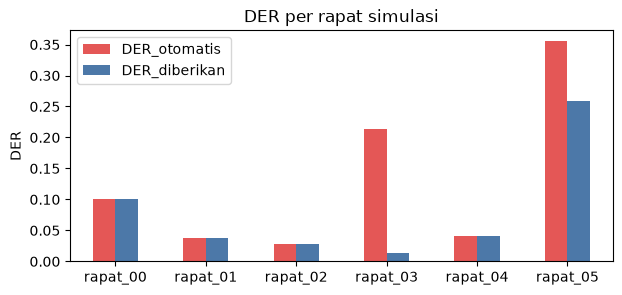

File dengan jumlah pembicara salah tebak: ['rapat_03', 'rapat_05']
Porsi detik salah-pembicara (mode otomatis) dari file itu: 94%


In [10]:
fig, ax = plt.subplots(figsize=(7, 3))
der[["DER_otomatis", "DER_diberikan"]].plot.bar(ax=ax, color=["#E45756", "#4C78A8"], rot=0)
ax.set_ylabel("DER")
ax.set_xlabel("")
ax.set_title("DER per rapat simulasi")
plt.show()

wrong_count = der[der.pembicara_terdeteksi != der.pembicara_ref]
share = wrong_count.salah_pembicara_otomatis_dtk.sum() / der.salah_pembicara_otomatis_dtk.sum()
print(f"File dengan jumlah pembicara salah tebak: {list(wrong_count.index)}")
print(f"Porsi detik salah-pembicara (mode otomatis) dari file itu: {share:.0%}")

## 3. Ringkasan

LLM membaca transkrip referensi, jadi skor di sini tidak terpengaruh kesalahan ASR. Dengan hanya 4 dokumen, angka ini indikatif.

In [11]:
pd.DataFrame(results["summary"]).set_index("item").rename(
    columns={"rouge_l": "ROUGE-L F1", "bertscore": "BERTScore F1"}
).round(3)

,ROUGE-L F1,BERTScore F1
item,,
naskah_01,0.492,0.755
naskah_02,0.452,0.781
naskah_03,0.315,0.749
naskah_04,0.650,0.825


## 4. Tindak lanjut

Item prediksi dipasangkan satu lawan satu dengan item referensi jika token F1 tugas atau kutipannya minimal ambang (`evaluation.action_match_threshold`). Tabel ini menunjukkan status tiap item.

In [12]:
threshold = evaluation.action_match_threshold
action_rows = []
for item in items:
    if item.summary is None:
        continue
    reference = load_summary(item.summary).tindak_lanjut
    predicted = Summary.model_validate_json(
        (OUTPUT_DIR / "summaries" / f"{item.item_id}.json").read_text(encoding="utf-8")
    ).tindak_lanjut
    pairs = dict(match_items(predicted, reference, threshold))
    for index, action in enumerate(predicted):
        ref_index = pairs.get(index)
        if ref_index is None:
            best = max(reference, key=lambda ref: item_similarity(action, ref), default=None)
            similarity = item_similarity(action, best) if best else 0.0
        else:
            best = reference[ref_index]
            similarity = item_similarity(action, best)
        owner_ok = None
        if ref_index is not None:
            owner_ok = same_owner(action.penanggung_jawab, best.penanggung_jawab)
        action_rows.append(
            {
                "dokumen": item.item_id,
                "status": "cocok" if ref_index is not None else "berlebih",
                "tugas_prediksi": action.tugas,
                "pj_prediksi": action.penanggung_jawab,
                "referensi_terdekat": best.tugas if best else None,
                "pj_referensi": best.penanggung_jawab if best else None,
                "kemiripan": round(similarity, 2),
                "pj_benar": owner_ok,
            }
        )
    for ref_index, action in enumerate(reference):
        if ref_index not in pairs.values():
            action_rows.append(
                {
                    "dokumen": item.item_id,
                    "status": "terlewat",
                    "tugas_prediksi": None,
                    "pj_prediksi": None,
                    "referensi_terdekat": action.tugas,
                    "pj_referensi": action.penanggung_jawab,
                    "kemiripan": None,
                    "pj_benar": None,
                }
            )

actions = pd.DataFrame(action_rows)
print(actions.status.value_counts().to_string())
actions

status
cocok       7
berlebih    5
terlewat    2


,dokumen,status,tugas_prediksi,pj_prediksi,referensi_terdekat,pj_referensi,kemiripan,pj_benar
0,naskah_01,cocok,Pinjam cangkul dan gerobak dari RT enam sebelum hari Sabtu.,Pak Joko,Meminjam cangkul dan gerobak dari RT enam,Pak Joko (Pembicara 3),1.00,True
1,naskah_01,cocok,Koordinasi ibu-ibu PKK untuk menyiapkan sarapan.,Bu Sari,Mengoordinasi ibu-ibu PKK menyiapkan sarapan kerja bakti,Bu Sari (Pembicara 2),1.00,True
2,naskah_01,cocok,Membuat jadwal ronda dan membagikan ke grup WhatsApp warga paling lambat hari Jumat.,Pembicara 1,Membuat jadwal ronda dan membagikannya ke grup WhatsApp warga,Pak RT (Pembicara 1),1.00,True
3,naskah_01,berlebih,Pasang CCTV di pintu masuk gang.,Bu,Meminjam cangkul dan gerobak dari RT enam,Pak Joko (Pembicara 3),0.08,None
4,naskah_02,berlebih,Wawancarai petugas puskesmas dekat kampus minggu ini.,Nisa,Mewawancarai petugas puskesmas dan menulis hasilnya di dokumen bersama,Nisa (Pembicara 3),0.25,None
5,naskah_02,cocok,Buat desain tampilan di Figma minimal lima halaman.,Raka,Membuat desain tampilan di Figma minimal lima halaman,Raka (Pembicara 2),0.88,True
6,naskah_02,cocok,Bikin bab satu sama bab dua laporannya sampai hari Minggu.,Pembicara 1,Menulis bab satu dan bab dua laporan,Dim (Pembicara 1),1.00,True
7,naskah_02,berlebih,Latihan bersama presentasi tanggal satu Desember di perpustakaan jam empat sore.,Semua,Mewawancarai petugas puskesmas dan menulis hasilnya di dokumen bersama,Nisa (Pembicara 3),0.20,None
8,naskah_02,terlewat,None,None,Mewawancarai petugas puskesmas dan menulis hasilnya di dokumen bersama,Nisa (Pembicara 3),NaN,None
9,naskah_03,berlebih,"Mulai dari sepuluh menit sehari saja, pilih buku yang memang disukai, tidak usah langsung buku yang berat.",Pendengar,None,None,0.00,None


### Item yang gagal dicocokkan tapi mirip

Item "berlebih" dengan kemiripan mendekati ambang bisa jadi benar, hanya kata-katanya beda (misalnya "Buat" lawan "Membuat"). Metrik token F1 tidak melakukan stemming.

In [13]:
near = actions[(actions.status == "berlebih") & (actions.kemiripan >= 0.25)]
near[["dokumen", "tugas_prediksi", "referensi_terdekat", "kemiripan"]]

,dokumen,tugas_prediksi,referensi_terdekat,kemiripan
4,naskah_02,Wawancarai petugas puskesmas dekat kampus minggu ini.,Mewawancarai petugas puskesmas dan menulis hasilnya di dokumen bersama,0.25
11,naskah_04,Buat desain poster promonya.,Membuat desain poster promo beli lima gratis satu,0.33


In [14]:
wrong_owner = actions[actions.pj_benar == False]  # noqa: E712
wrong_owner[["dokumen", "tugas_prediksi", "pj_prediksi", "pj_referensi"]]

,dokumen,tugas_prediksi,pj_prediksi,pj_referensi
12,naskah_04,"Cari pemasok gula aren cadangan dan bandingkan harganya, laporkan ke saya hari Jumat.",Pembicara 1,Bu Wati (Pembicara 2)


### Audit manual tindak lanjut

Lima prediksi tidak cocok dengan referensi. Setelah dicek ke transkrip:

| Prediksi | Penilaian | Alasan |
| --- | --- | --- |
| Pasang CCTV di pintu masuk gang (naskah_01) | Salah | Usul ditunda: "biayanya belum cukup, kita bahas lagi bulan depan". LLM menganggap usulan sebagai tugas. |
| Wawancarai petugas puskesmas (naskah_02) | Benar, kurang lengkap | Tugas dan orangnya benar. Tenggat diambil dari permintaan ("minggu ini"), bukan dari jawaban Nisa ("hari Kamis"). |
| Latihan bersama 1 Desember (naskah_02) | Abu-abu | Kegiatan ini disepakati semua peserta. Referensi tidak memasukkannya karena tidak punya satu penanggung jawab. |
| Saran membaca 10 menit sehari (naskah_03) | Salah | Saran podcast untuk pendengar, bukan tugas. |
| Buat desain poster promo (naskah_04) | Benar | Ditolak metrik karena "Buat" lawan "Membuat" dan referensi lebih panjang. Token F1 tidak melakukan stemming. |

Jika dua item yang benar ikut dihitung cocok, precision naik dari 58% menjadi 75% (9 dari 12) dan recall dari 78% menjadi 100% (9 dari 9). Metrik otomatis di sini cenderung terlalu keras.

Satu penanggung jawab salah (naskah_04): pada "Bu Wati, tolong cari pemasok ..., laporkan ke saya", LLM memilih pembicara yang memberi perintah, bukan orang yang dipanggil.

## Kesimpulan

**ASR**

- 30% ucapan bebas kesalahan dan median WER per ucapan 6.9%. Kesalahan menumpuk di sedikit ucapan yang berisi nama diri asing (Greenland, Uppsala, Geospiza, Scotturb).
- Lebih dari separuh kesalahan kata adalah bunyi atau ejaan yang mirip ("pesisir" lawan "pisisir", "pakaian" lawan "pakean", "finch" lawan "vince"). Perbaikan yang paling menjanjikan adalah memberi Whisper daftar istilah lewat `initial_prompt` atau `hotwords`, misalnya nama peserta dan istilah rapat.
- Sekitar 15% kesalahan hanya soal format angka ("17" lawan "tujuh belas") atau spasi ("ibukota" lawan "ibu kota"). Tanpa itu, WER turun dari 10.6% ke sekitar 9.0%.
- Keyakinan kata dari Whisper berkorelasi cukup kuat dengan WER (Spearman -0.67). Bagian transkrip dengan keyakinan rendah layak ditandai untuk dicek manusia.
- Satu ucapan (fleurs_009) hilang seluruhnya karena probabilitas VAD tidak pernah mencapai 0.5. Ambang 0.3 hanya memulihkan 3.4 dari 9.7 detik, jadi ambang default tidak diubah untuk satu kasus dari 100. Untuk rekaman yang pelan, matikan VAD atau turunkan ambangnya.

**Diarization**

- Jika jumlah pembicara diberikan, 4 dari 6 rapat punya DER di bawah 5%. rapat_00 berada di 10%, sebagian besar karena alarm palsu di jeda antar-giliran. Kesalahan terbesar datang dari salah menebak jumlah pembicara: rapat_03 (5 lawan 3) dan rapat_05 (2 lawan 3) menyumbang 94% detik salah-pembicara di mode otomatis.
- rapat_05 tetap 25.9% meski jumlahnya benar. Dua pembacanya bersuara mirip, kasus yang sulit untuk embedding pembicara. Di demo, isi kolom jumlah pembicara jika diketahui.

**Ringkasan dan tindak lanjut**

- Skor ringkasan terendah ada di podcast (naskah_03, ROUGE-L 0.315). Obrolan tanpa agenda tidak punya keputusan yang jelas untuk dirangkum, dan ringkasan referensinya lebih bebas.
- Kesalahan LLM yang berulang adalah membedakan usulan dari keputusan, dan saran umum dari tugas. Arah perbaikan: contoh negatif di prompt (usul yang ditunda, saran ke pendengar) dan aturan bahwa penanggung jawab adalah orang yang dipanggil.